<a href="https://colab.research.google.com/github/Amunikeqtip/Amunikeqtip.github.io/blob/main/Hello_AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from torchvision.models import resnet50, ResNet50_Weights

weights = ResNet50_Weights.DEFAULT
model = resnet50(weights=weights)
model.eval()

preprocess = weights.transforms()
categories = weights.meta["categories"]

print("Pretrained ResNet-50 loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 154MB/s]


Pretrained ResNet-50 loaded successfully!


Saving WhatsApp Image 2026-06-05 at 12.49.07 (1).jpeg to WhatsApp Image 2026-06-05 at 12.49.07 (1).jpeg


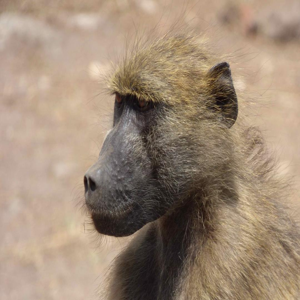

Uploaded: WhatsApp Image 2026-06-05 at 12.49.07 (1).jpeg


In [10]:
from google.colab import files
from PIL import Image
from IPython.display import display
import io

uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image and run this cell again.")

filename = next(iter(uploaded))
image = Image.open(io.BytesIO(uploaded[filename])).convert("RGB")

display(image.copy().resize((300, 300)))
print("Uploaded:", filename)

In [11]:
# Prepare the image and add a batch dimension.
input_tensor = preprocess(image).unsqueeze(0)

# Run the model without calculating training gradients.
with torch.inference_mode():
    scores = model(input_tensor)
    probabilities = torch.softmax(scores[0], dim=0)

# Display the five highest-scoring categories.
top_probabilities, top_indices = probabilities.topk(5)

print("Hello AI! Here are my predictions:\n")

for probability, index in zip(top_probabilities, top_indices):
    label = categories[index.item()]
    print(f"{label}: {probability.item():.2%}")

Hello AI! Here are my predictions:

baboon: 48.01%
patas: 0.40%
macaque: 0.35%
guenon: 0.18%
siamang: 0.16%
